In [ ]:
import pandas as pd
import re

from ydata_profiling.utils.cache import cache_file
from ydata_profiling import ProfileReport

data_folder = "./data/datos_imputados_2023/"

df_dinagua = pd.read_parquet(data_folder+"SL_HIDRO_DINAGUA_SLC_2011_2023.parquet")
df_inia = pd.read_parquet(data_folder+"SL_MET_INIA_2011_2023.parquet")
df_inumet = pd.read_parquet(data_folder+"SL_MET_INUMET_SLC_1980_2023.parquet")
df_dinacea = pd.read_parquet(data_folder+"SL_CA_DINACEA_SLC_2011_2022.parquet")

df_inumet_not_imputed = pd.read_parquet(data_folder+"not_imputed/SL_MET_INUMET_1980_2023.parquet")
df_dinagua_not_imputed = pd.read_parquet(data_folder+"not_imputed/SL_HIDRO_DINAGUA_1980_2023.parquet")


In [2]:
import pandas as pd
import re

from ydata_profiling.utils.cache import cache_file
from ydata_profiling import ProfileReport
data_folder = "./data/All data/"

df_inumet = pd.read_parquet(data_folder+"SL_MET_INUMET_SLC_NOIMP_1980_2023.parquet")
df_inumet

,[25 de Agosto] Precipitacion (P) [mm],[Cerro Colorado] Precipitacion (P) [mm],[Florida] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Mendoza] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm],[Villa 25 de Mayo] Precipitacion (P) [mm],[Villa Cardal] Precipitacion (P) [mm]
date,,,,,,,,,,
1980-01-01,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1980-01-02,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1980-01-03,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1980-01-04,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1980-01-05,13.0,32.0,NaN,2.0,9.0,13.0,9.0,4.0,1.0,7.0
...,...,...,...,...,...,...,...,...,...,...
2023-06-23,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-06-24,0.1,0.0,0.0,0.2,0.0,0.0,0.0,0.2,0.1,0.1
2023-06-25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
# Print Caudal and Nivel the last 5 overlapping years for Florida
station_dinagua = [("Caudal (Q) [m3/s]", "Florida (Puente Ruta 5)"), ("Nivel de agua (h) [m]", "Florida (Puente Ruta 5)")]
station_inumet = [("Precipitacion (P) [mm]", "Florida")]

# Extract years
years1 = set(df_inumet.index.year)
years2 = set(df_dinagua.index.year)

# Find overlapping years
overlap_years = sorted(years1.intersection(years2))

# Last 5 overlapping years
last_5_years = overlap_years[-4:]

# Filter DataFrames to keep full dates from those years
df_inumet_last5 = df_inumet[df_inumet.index.year.isin(last_5_years)]
df_dinagua_last5 = df_dinagua[df_dinagua.index.year.isin(last_5_years)]

df_inumet_last5_florida = df_inumet_last5.loc[:,station_inumet]
df_dinagua_last5_florida = df_dinagua_last5.loc[:,station_dinagua]

df_inumet_not_imputed_florida = df_inumet_not_imputed.loc[df_inumet.index.year.isin(last_5_years),station_inumet]
df_dinagua_not_imputed_florida = df_dinagua_not_imputed.loc[df_dinagua.index.year.isin(last_5_years),station_dinagua]

df_inumet_not_imputed_florida_mask = df_inumet_not_imputed_florida.isnull()
df_dinagua_not_imputed_florida_mask = df_dinagua_not_imputed_florida.isnull()

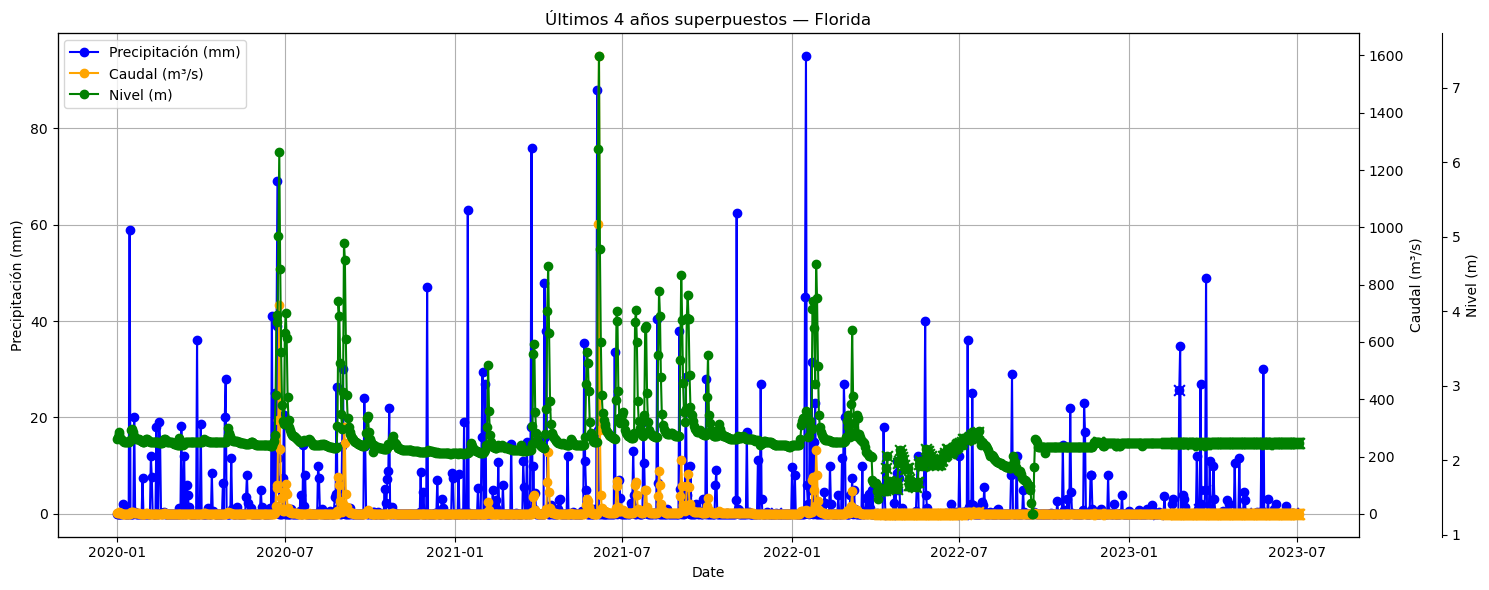

In [32]:
import matplotlib.pyplot as plt

# --- Extract Series correctly from MultiIndex ---

# INUMET precipitation
inumet_series = df_inumet_last5.loc[:, station_inumet[0]]

inumet_not_imp = df_inumet_not_imputed.loc[
    df_inumet_not_imputed.index.year.isin(last_5_years),
    station_inumet[0]
]

# DINAGUA caudal
caudal_series = df_dinagua_last5.loc[:, station_dinagua[0]]

caudal_not_imp = df_dinagua_not_imputed.loc[
    df_dinagua_not_imputed.index.year.isin(last_5_years),
    station_dinagua[0]
]

# DINAGUA nivel
nivel_series = df_dinagua_last5.loc[:, station_dinagua[1]]

nivel_not_imp = df_dinagua_not_imputed.loc[
    df_dinagua_not_imputed.index.year.isin(last_5_years),
    station_dinagua[1]
]

# --- Missing masks ---
inumet_missing = inumet_not_imp.isnull()
caudal_missing = caudal_not_imp.isnull()
nivel_missing  = nivel_not_imp.isnull()

# --- Create axes ---
fig, ax1 = plt.subplots(figsize=(15,6))

# Second axis
ax2 = ax1.twinx()

# Third axis
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("outward", 60))

# Bring precipitation axis to front
# ax1.set_zorder(3)
# ax2.set_zorder(2)
# ax3.set_zorder(1)

# Make background transparent so others stay visible
ax1.patch.set_visible(False)

# --- Plot lines ---

# Colors
c_precip = "blue"
c_caudal = "orange"
c_nivel  = "green"

# Lines

ax2.plot(
    caudal_series.index,
    caudal_series,
    marker='o',
    linestyle='-',
    color=c_caudal,
    label='Caudal (m³/s)',
    zorder=1
)

ax3.plot(
    nivel_series.index,
    nivel_series,
    marker='o',
    linestyle='-',
    color=c_nivel,
    label='Nivel (m)',
    zorder=2
)

ax1.plot(
    inumet_series.index,
    inumet_series,
    marker='o',
    linestyle='-',
    color=c_precip,
    label='Precipitación (mm)',
    zorder=3
)

# Crosses
ax1.scatter(
    inumet_series.index[inumet_missing],
    inumet_series[inumet_missing],
    marker='x',
    s=60,
    color=c_precip,
    zorder=4
)

ax2.scatter(
    caudal_series.index[caudal_missing],
    caudal_series[caudal_missing],
    marker='x',
    s=60,
    color=c_caudal
)

ax3.scatter(
    nivel_series.index[nivel_missing],
    nivel_series[nivel_missing],
    marker='x',
    s=60,
    color=c_nivel
)

# --- Labels ---
ax1.set_xlabel("Date")

ax1.set_ylabel("Precipitación (mm)")
ax2.set_ylabel("Caudal (m³/s)")
ax3.set_ylabel("Nivel (m)")

# --- Legend (combine all axes) ---
lines = (
    ax1.get_lines()
    + ax2.get_lines()
    + ax3.get_lines()
)

labels = [l.get_label() for l in lines]

ax1.legend(lines, labels, loc="upper left")

# --- Grid ---
ax1.grid(True)

plt.title("Últimos 4 años superpuestos — Florida")

plt.tight_layout()
plt.show()

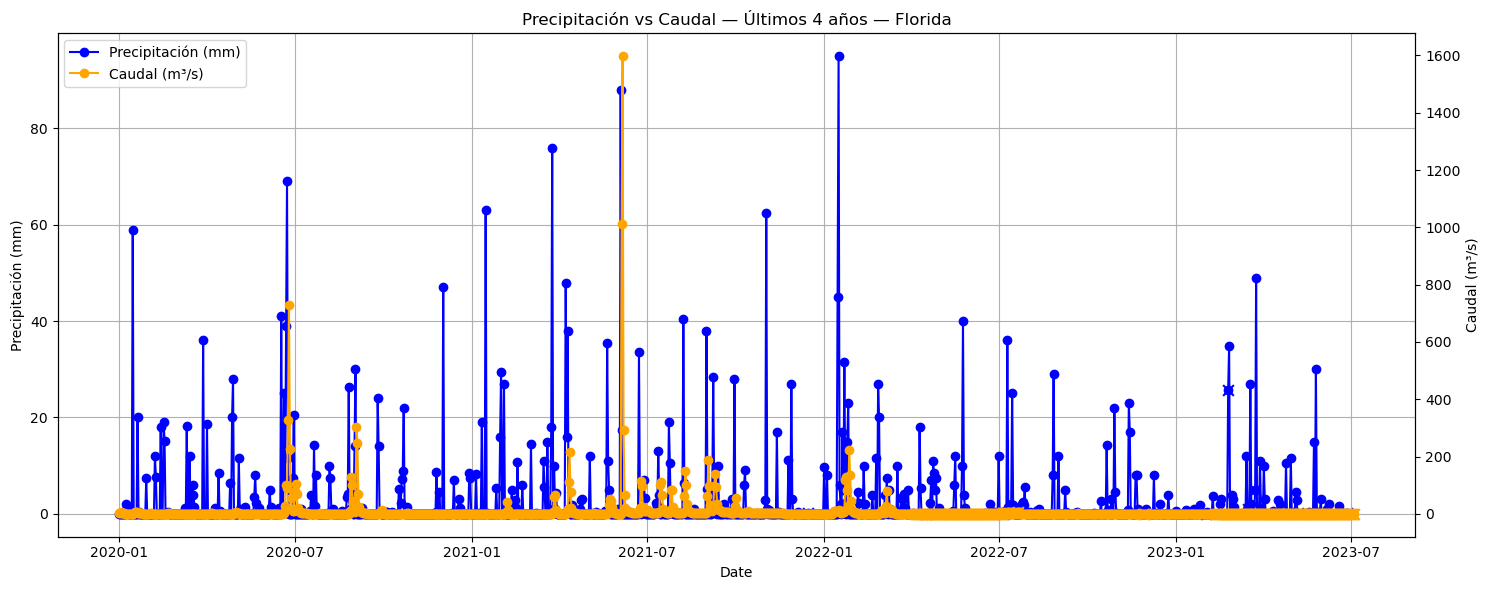

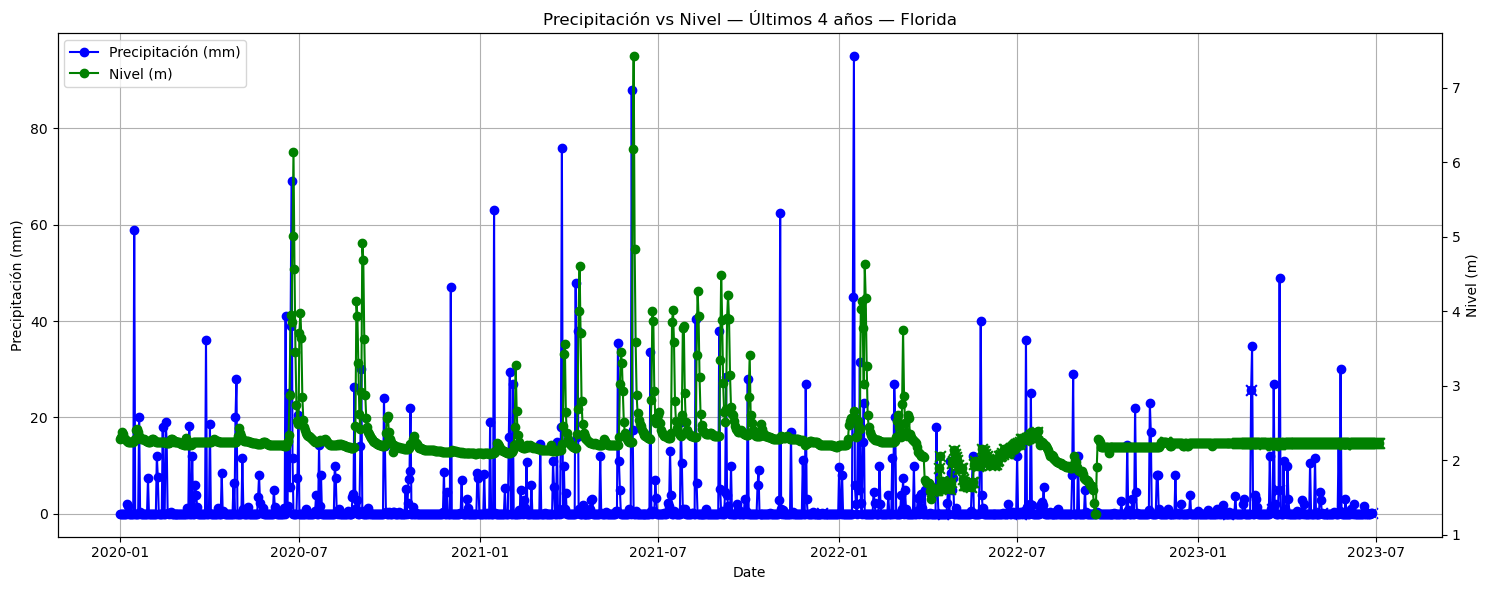

In [33]:
import matplotlib.pyplot as plt

# --- Colors ---
c_precip = "blue"
c_caudal = "orange"
c_nivel  = "green"

# =========================================================
# PLOT 1 — Caudal + Precipitación
# =========================================================

fig, ax1 = plt.subplots(figsize=(15,6))
ax2 = ax1.twinx()

# Lines
ax1.plot(
    inumet_series.index,
    inumet_series,
    marker='o',
    linestyle='-',
    color=c_precip,
    label='Precipitación (mm)'
)

ax2.plot(
    caudal_series.index,
    caudal_series,
    marker='o',
    linestyle='-',
    color=c_caudal,
    label='Caudal (m³/s)'
)

# Missing crosses
ax1.scatter(
    inumet_series.index[inumet_missing],
    inumet_series[inumet_missing],
    marker='x',
    s=60,
    color=c_precip
)

ax2.scatter(
    caudal_series.index[caudal_missing],
    caudal_series[caudal_missing],
    marker='x',
    s=60,
    color=c_caudal
)

# Labels
ax1.set_xlabel("Date")
ax1.set_ylabel("Precipitación (mm)")
ax2.set_ylabel("Caudal (m³/s)")

# Legend
lines = ax1.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

ax1.grid(True)

plt.title("Precipitación vs Caudal — Últimos 4 años — Florida")

plt.tight_layout()
plt.show()


# =========================================================
# PLOT 2 — Nivel + Precipitación
# =========================================================

fig, ax1 = plt.subplots(figsize=(15,6))
ax2 = ax1.twinx()

# Lines
ax1.plot(
    inumet_series.index,
    inumet_series,
    marker='o',
    linestyle='-',
    color=c_precip,
    label='Precipitación (mm)'
)

ax2.plot(
    nivel_series.index,
    nivel_series,
    marker='o',
    linestyle='-',
    color=c_nivel,
    label='Nivel (m)'
)

# Missing crosses
ax1.scatter(
    inumet_series.index[inumet_missing],
    inumet_series[inumet_missing],
    marker='x',
    s=60,
    color=c_precip
)

ax2.scatter(
    nivel_series.index[nivel_missing],
    nivel_series[nivel_missing],
    marker='x',
    s=60,
    color=c_nivel
)

# Labels
ax1.set_xlabel("Date")
ax1.set_ylabel("Precipitación (mm)")
ax2.set_ylabel("Nivel (m)")

# Legend
lines = ax1.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

ax1.grid(True)

plt.title("Precipitación vs Nivel — Últimos 4 años — Florida")

plt.tight_layout()
plt.show()